# DSA 2050A — Week 9 practical GROUP lab 
## Model selection and defensible evaluation | Python + GitHub

**Group name/number:** [TO FILL]  |  **Members and student IDs:** [TO FILL — see README.md]

**Scenario.** A fictional Kenyan internet provider wants to identify which customers might stop using its services. The task is not simply to obtain the highest score: it is to **choose, document and defend one suitable model using evidence**.

**Data notice.** The records are synthetic, created for teaching. They are not real customers.

**How this notebook is organised.** Each Part of the lab handout (A–G) is restated below, followed by the starter code (unchanged) and then a  Answer cell written from the real outputs. Run cells top to bottom. The final-test cell must run only once.

## Part A — Set up in VS Code (10 minutes)
**Handout steps:** (1) Extract the ZIP and open VS Code. (2) File → Open Folder → `DSA2050_Week9_GitHub_Lab`. (3) Terminal → New Terminal; check `python --version` (3.10–3.13 recommended). (4) Create a virtual environment (`py -m venv .venv` on Windows; `python3 -m venv .venv` on macOS/Linux). (5) Ctrl+Shift+P → *Python: Select Interpreter* → `.venv`. (6) `python -m pip install -r requirements.txt`. (7) Open this notebook → **Select Kernel** → the same `.venv` → run cells from the top. If `pip` is not recognised, use `python -m pip`.

**Group discussion question:** *Why must the final test not be consulted before choosing a model?*

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
assert (DATA / 'churn_development.csv').exists(), 'Open the project folder in VS Code.'
print('Project:', ROOT.resolve())
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)

Project: /home/claude/repo/DSA2050_Week9_GitHub_Lab
Python: 3.12.3 scikit-learn: 1.9.1


### Why must the final test set remain sealed until the model is chosen?

The final test set represents future, unseen customers and should only be used to estimate how well the selected model performs. Using it during model selection or hyperparameter tuning introduces data leakage and selection bias, resulting in overly optimistic performance estimates. Therefore, all model selection must be based on cross-validation using the development data. The final model choice should be frozen before evaluating the test set once to obtain an unbiased estimate of its performance.

## Part B — Data inspection and leakage prevention (15 minutes)
**Step 1 — Inspect development data.** Load the development CSV; print shape, class balance and missing-value counts. No test data is read here.

**Step 2 — Exclude forbidden columns.** Drop `churn` (target), `customer_id` and `cancellation_confirmed` from the features.

**Record:** *What is the unit of analysis? Which features could have existed at prediction time? Why is `cancellation_confirmed` a leak?*

In [2]:
dev = pd.read_csv(DATA / 'churn_development.csv')
print('Shape:', dev.shape)
print('Churn rate:', round(dev['churn'].mean(), 3))
print('Missing values:\n', dev.isna().sum())
display(dev.head())

TARGET = 'churn'
LEAKAGE_OR_IDS = ['churn', 'customer_id', 'cancellation_confirmed']
X_dev = dev.drop(columns=LEAKAGE_OR_IDS)
y_dev = dev[TARGET].astype(int)
print('Allowed features:', X_dev.columns.tolist())
assert 'cancellation_confirmed' not in X_dev.columns
assert 'customer_id' not in X_dev.columns

Shape: (2720, 11)
Churn rate: 0.335
Missing values:
 customer_id                 0
tenure_months               0
monthly_charges_kes       156
support_tickets_90d       120
service_calls_90d           0
plan_type                   0
region                     93
autopay                     0
customer_segment            0
cancellation_confirmed      0
churn                       0
dtype: int64


,customer_id,tenure_months,monthly_charges_kes,support_tickets_90d,service_calls_90d,plan_type,region,autopay,customer_segment,cancellation_confirmed,churn
0,CUST-12486,22,1943.94,1.0,2,Basic,Mombasa,Yes,Established,Active,0
1,CUST-12546,40,5003.13,1.0,0,Premium,Nairobi,No,Established,Active,0
2,CUST-11112,57,2796.23,1.0,1,Basic,Nairobi,Yes,Established,Active,0
3,CUST-12753,33,4697.39,NaN,0,Premium,Nairobi,Yes,Established,Active,0
4,CUST-10753,53,4330.27,2.0,1,Standard,Mombasa,No,Established,Active,0


Allowed features: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d', 'plan_type', 'region', 'autopay', 'customer_segment']


In [3]:
# Evidence for the leakage answer: how does cancellation_confirmed relate to churn?
print(pd.crosstab(dev['cancellation_confirmed'], dev['churn']))
print('\nSegment sizes:\n', dev['customer_segment'].value_counts())

churn                      0    1
cancellation_confirmed           
Active                  1810    0
Cancelled                  0  910

Segment sizes:
 customer_segment
Established    2268
New             452
Name: count, dtype: int64




**(a) Target:** `churn` (1 = cancelled, 0 = stayed). Of the 2,720 development customers, 910 (33.5%) churned and 1,810 (66.5%) stayed, indicating class imbalance.

**(b) Unit of analysis:** One customer account, with each row representing an individual customer's characteristics and churn status.

**(c) Leakage column:** `cancellation_confirmed`. It directly reveals the cancellation outcome, making it unavailable at prediction time. Including it would cause data leakage and produce misleading model performance.

**(d) Why should `customer_id` not be used as a predictor?**

`customer_id` is an arbitrary unique identifier with no meaningful predictive information. Including it could encourage memorisation rather than learning patterns that generalise to new customers.

## Part C — Safe preprocessing and cross-validation (20 minutes)
**Step 3 — Put transformations inside a pipeline.** Numeric columns: median imputation + scaling. Categorical columns: most-frequent imputation + one-hot encoding. Because preprocessing sits inside a `Pipeline`, it is re-fitted on the training part of each fold only. All models use the same `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

*Analogy:* five mock exams — four parts are practice, one is the unseen mock, and every candidate faces the same mocks. The final exam (test CSV) stays sealed.

In [4]:
num_cols = X_dev.select_dtypes(include='number').columns.tolist()
cat_cols = X_dev.select_dtypes(exclude='number').columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
category_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', category_pipe, cat_cols)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Numeric:', num_cols)
print('Categorical:', cat_cols)
print('Same fixed CV:', cv)

Numeric: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d']
Categorical: ['plan_type', 'region', 'autopay', 'customer_segment']
Same fixed CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


**Step 4 — Test a dummy baseline.** *Predict the resulting F1 and explain why majority-class accuracy could sound impressive while missing churners.*

In [5]:
dummy_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
metrics = {'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}
baseline_scores = cross_validate(dummy_pipe, X_dev, y_dev, cv=cv, scoring=metrics)
print('Baseline fold F1:', np.round(baseline_scores['test_f1'], 3))
print('Baseline mean F1:', round(baseline_scores['test_f1'].mean(), 3))

Baseline fold F1: [0. 0. 0. 0. 0.]
Baseline mean F1: 0.0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_clas



**Predicted and observed F1:** 0.000 across all five folds. The dummy classifier always predicts the majority class (stay), resulting in zero recall and an F1 score of zero.

**Why can majority-class accuracy be misleading?**

Since 66.5% of customers stayed, predicting that all customers will stay could achieve 66.5% accuracy while failing to identify any churners. Therefore, F1 is more useful for evaluating the model's ability to identify customers at risk of churning.

## Part D — Fair comparison and small grid search (25 minutes)
**Step 5 — Compare candidates with identical folds.** Both candidates use the **same** `StratifiedKFold` object and the **same** selection rule (F1). The notebook writes `reports/experiment_log.csv`.

| Model | Hyperparameter | Values evaluated |
|---|---|---|
| Logistic regression | `C` | 0.1, 1, 10 |
| Decision tree | `max_depth` | 3, 5, 8 |

Do not keep changing the grid until a lucky score appears. Record mean F1, F1 standard deviation, the five fold F1 scores, mean precision and mean recall for the best configuration of each family.

**Decision question:** *Is a 0.005 mean-F1 improvement convincing if the alternative model is more variable across folds? Explain your choice.*

In [6]:
candidates = {
    'Logistic regression': (
        LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.1, 1, 10]}
    ),
    'Decision tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 8]}
    )
}
searches = {}
logs = []
for name, (model, grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=metrics,
        refit='f1', n_jobs=1, return_train_score=True
    )
    search.fit(X_dev, y_dev)
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    for _, r in results.iterrows():
        row = {
            'model': name, 'settings': str(r['params']),
            'mean_f1': float(r['mean_test_f1']),
            'std_f1': float(r['std_test_f1']),
            'mean_precision': float(r['mean_test_precision']),
            'mean_recall': float(r['mean_test_recall'])
        }
        for i in range(5):
            row[f'fold_{i+1}_f1'] = float(r[f'split{i}_test_f1'])
        logs.append(row)

experiment_log = pd.DataFrame(logs).sort_values('mean_f1', ascending=False)
experiment_log.to_csv(REPORTS / 'experiment_log.csv', index=False)
display(experiment_log.round(3))
print('Saved:', REPORTS / 'experiment_log.csv')

,model,settings,mean_f1,std_f1,mean_precision,mean_recall,fold_1_f1,fold_2_f1,fold_3_f1,fold_4_f1,fold_5_f1
1,Logistic regression,{'model__C': 1},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
2,Logistic regression,{'model__C': 10},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
0,Logistic regression,{'model__C': 0.1},0.465,0.054,0.625,0.371,0.388,0.533,0.454,0.432,0.519
3,Decision tree,{'model__max_depth': 3},0.398,0.049,0.566,0.318,0.392,0.457,0.316,0.437,0.391
4,Decision tree,{'model__max_depth': 5},0.382,0.023,0.583,0.287,0.376,0.383,0.365,0.362,0.426
5,Decision tree,{'model__max_depth': 8},0.372,0.051,0.495,0.300,0.298,0.439,0.338,0.370,0.417


Saved: /home/claude/repo/DSA2050_Week9_GitHub_Lab/reports/experiment_log.csv


**Step 6 — Examine variation and select a candidate.** Compare the best logistic regression with the best tree, then choose one. (A different choice from the automatic highest-F1 default is allowed with a defensible reason.)

In [7]:
best_by_model = (experiment_log.sort_values('mean_f1', ascending=False)
                 .drop_duplicates(subset='model').reset_index(drop=True))
display(best_by_model[['model','mean_f1','std_f1','mean_recall','mean_precision']].round(3))

# Change only if your explanation supports the different choice.
CHOSEN_MODEL = best_by_model.iloc[0]['model']
assert CHOSEN_MODEL in searches
chosen_search = searches[CHOSEN_MODEL]
chosen_pipeline = chosen_search.best_estimator_
print('Chosen:', CHOSEN_MODEL)
print('Settings:', chosen_search.best_params_)
print('Development CV F1:', round(chosen_search.best_score_, 3))

,model,mean_f1,std_f1,mean_recall,mean_precision
0,Logistic regression,0.470,0.053,0.378,0.624
1,Decision tree,0.398,0.049,0.318,0.566


Chosen: Logistic regression
Settings: {'model__C': 1}
Development CV F1: 0.47


### Answer — Comparison table (all numbers from `reports/experiment_log.csv`)

| Model | Setting | Mean F1 | SD F1 | Mean precision | Mean recall | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|---|---|---|---|---|
| **Logistic regression (best)** | **C = 1** | **0.470** | **0.053** | **0.624** | **0.378** | 0.391 | 0.534 | 0.472 | 0.434 | 0.519 |
| Logistic regression | C = 10 | 0.470 | 0.053 | 0.624 | 0.378 | (identical to C = 1) | | | | |
| Logistic regression | C = 0.1 | 0.465 | 0.054 | 0.625 | 0.371 | | | | | |
| **Decision tree (best)** | **max_depth = 3** | **0.398** | **0.049** | **0.566** | **0.318** | 0.392 | 0.457 | 0.316 | 0.437 | 0.391 |
| Decision tree | max_depth = 5 | 0.382 | 0.023 | 0.583 | 0.287 | | | | | |
| Decision tree | max_depth = 8 | 0.372 | 0.051 | 0.495 | 0.300 | | | | | |

*(C = 1 and C = 10 tie exactly; scikit-learn keeps the first, C = 1, which is also the more regularised and therefore the more conservative choice.)*

**Choice:** Logistic Regression, `C = 1`.

**Reason:** Logistic Regression performed better, achieving a mean F1 score of 0.470 compared to 0.398 for the Decision Tree. It also achieved higher precision (0.624) and recall (0.378), making it the stronger candidate for final model selection.

## Part E — Errors, subgroups and model reliance (25 minutes)
**Step 5 (handout) — Out-of-fold confusion matrix.** Use `cross_val_predict`. False negatives = customers predicted to stay who actually churned; false positives = customers flagged as high-risk who actually stayed. Save the plot to `reports/`.

              precision    recall  f1-score   support

           0       0.74      0.89      0.81      1810
           1       0.63      0.38      0.47       910

    accuracy                           0.72      2720
   macro avg       0.68      0.63      0.64      2720
weighted avg       0.70      0.72      0.69      2720



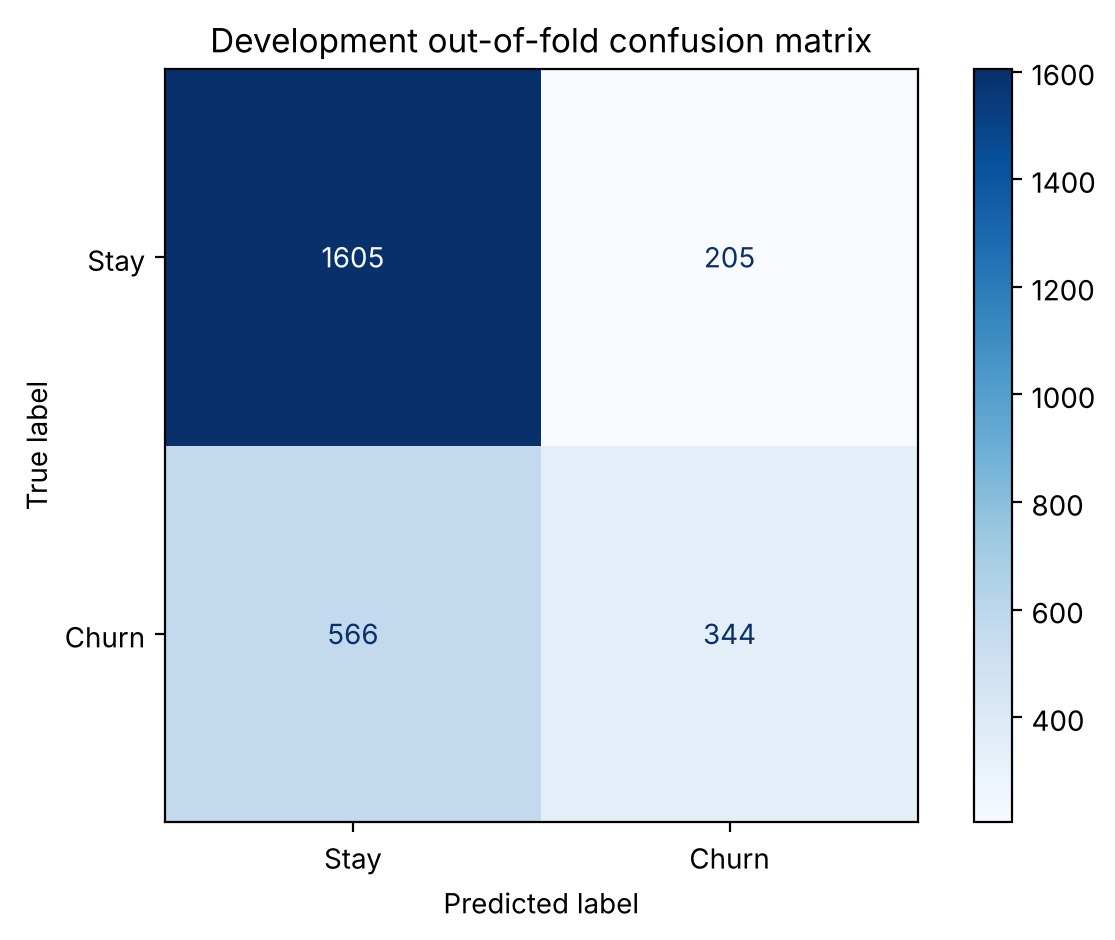

error_type
Correct           1949
False negative     566
False positive     205
Name: count, dtype: int64


,customer_id,customer_segment,plan_type,churn,prediction,error_type
5,CUST-12096,Established,Standard,1,0,False negative
10,CUST-11528,Established,Basic,1,0,False negative
12,CUST-12416,New,Basic,0,1,False positive
13,CUST-12232,Established,Basic,0,1,False positive
18,CUST-12749,Established,Standard,1,0,False negative
19,CUST-10694,Established,Basic,0,1,False positive
24,CUST-12737,Established,Basic,1,0,False negative
26,CUST-12112,Established,Basic,1,0,False negative


In [8]:
oof_pred = cross_val_predict(chosen_pipeline, X_dev, y_dev, cv=cv, method='predict')
print(classification_report(y_dev, oof_pred, zero_division=0))
cm = confusion_matrix(y_dev, oof_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=['Stay','Churn']).plot(cmap='Blues')
plt.title('Development out-of-fold confusion matrix')
plt.tight_layout()
plt.savefig(REPORTS / 'development_confusion_matrix.png', dpi=150)
plt.show()

errors = dev[['customer_id','customer_segment','plan_type','churn']].copy()
errors['prediction'] = oof_pred
errors['error_type'] = np.select([
    (errors.churn==1)&(errors.prediction==0),
    (errors.churn==0)&(errors.prediction==1)],
    ['False negative','False positive'],default='Correct')
print(errors.error_type.value_counts())
display(errors.query("error_type != 'Correct'").head(8))


**Interpretation of errors:**

- **False Negatives (566):** These are customers who actually churned but were predicted to stay. The model missed approximately 62.2% of actual churners, showing that it struggles to identify a substantial proportion of customers at risk of leaving.

- **False Positives (205):** These are customers who actually stayed but were incorrectly predicted to churn. This could lead the provider to spend resources on unnecessary retention offers or discounts.

- **Overall comparison:** False negatives outnumber false positives by approximately 2.8 to 1. This indicates that the model is more likely to miss customers who will churn than to incorrectly flag customers who will stay.

**Conclusion:** Although the model correctly classified 1,949 out of 2,720 customers (approximately 71.7%), the high number of false negatives shows that accuracy alone does not adequately measure its ability to identify churners. This supports the use of F1-score and recall when evaluating the model.


**Step 6 — Compare customer subgroups.** Using `customer_segment` (New vs Established), report customers, actual churners, recall, precision and false negatives for each group. A low score from a very small subgroup needs cautious language. *Is recall worse for new customers than established customers?*

In [9]:
group_rows = []
for group, part in errors.groupby('customer_segment'):
    true = part['churn'].to_numpy()
    pred = part['prediction'].to_numpy()
    group_rows.append({
        'segment': group, 'n_customers': len(part),
        'n_actual_churn': int(true.sum()),
        'recall': recall_score(true,pred,zero_division=0),
        'precision': precision_score(true,pred,zero_division=0),
        'false_negatives': int(((true==1)&(pred==0)).sum())
    })
subgroup = pd.DataFrame(group_rows)
subgroup.to_csv(REPORTS/'subgroup_metrics.csv',index=False)
display(subgroup.round(3))

,segment,n_customers,n_actual_churn,recall,precision,false_negatives
0,Established,2268,649,0.216,0.593,509
1,New,452,261,0.782,0.652,57




| Segment | Number of Customers | Actual Churners | Recall | Precision | False Negatives |
|---|---:|---:|---:|---:|---:|
| Established | 2,268 | 649 | 0.216 | 0.593 | 509 |
| New | 452 | 261 | 0.782 | 0.652 | 57 |

**Interpretation:**

- **Recall:** The model performs considerably better at identifying churners among New customers (0.782) than Established customers (0.216). This means it identifies approximately 78.2% of New customer churners but only 21.6% of Established customer churners.

- **False negatives:** The model misses 509 Established customers who actually churned, compared to 57 New customers. Established customers account for approximately 90% of all false negatives.

- **Precision:** Precision is relatively similar across the groups, at 0.593 for Established customers and 0.652 for New customers. This indicates that predictions of churn are somewhat more reliable for New customers.

- **Sample size consideration:** Although the New customer group is smaller (452 compared to 2,268 Established customers), it contains 261 actual churners. Therefore, the difference in recall is worth investigating, although the subgroup results should still be treated as indicative because they are based on out-of-fold predictions.

**Conclusion:** The model identifies New customer churn more effectively but struggles to detect churn among Established customers. The provider should investigate this performance gap and consider ways to improve churn detection for Established customers before deploying the model.

**Step 7 — Permutation importance.** On a held-out slice of development data, shuffle each feature and measure the fall in F1. Name the two features with the greatest mean F1 reduction. Explain why predictive reliance is not evidence of causation, and note that correlated features can share importance.

,feature,importance_mean,importance_std
0,tenure_months,0.079,0.024
2,support_tickets_90d,0.035,0.016
7,customer_segment,0.018,0.006
1,monthly_charges_kes,0.016,0.023
4,plan_type,0.015,0.015
5,region,0.006,0.013
3,service_calls_90d,0.003,0.007
6,autopay,0.002,0.017


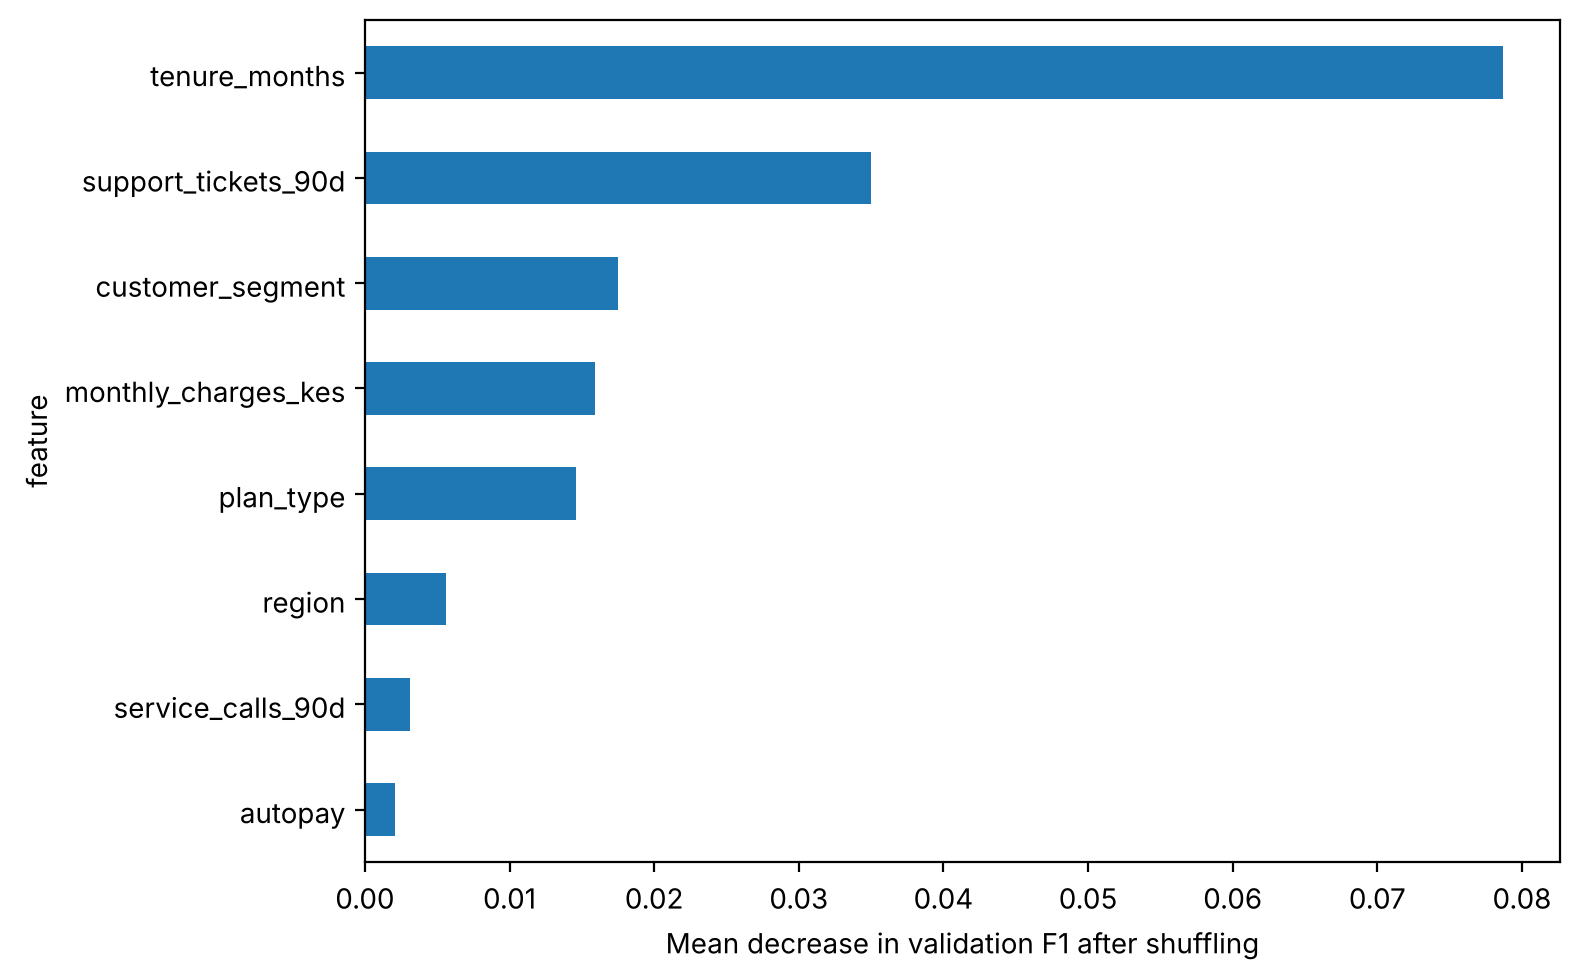

In [10]:
X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2050, stratify=y_dev
)
interpret_model = chosen_pipeline
interpret_model.fit(X_inner,y_inner)
importance = permutation_importance(
    interpret_model,X_validation,y_validation,
    scoring='f1', n_repeats=5,random_state=42,n_jobs=1
)
importance_table = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std
}).sort_values('importance_mean',ascending=False)
importance_table.to_csv(REPORTS/'permutation_importance.csv',index=False)
display(importance_table.round(3))
ax = importance_table.sort_values('importance_mean').plot.barh(
    x='feature',y='importance_mean',legend=False,figsize=(8,5))
ax.set_xlabel('Mean decrease in validation F1 after shuffling')
plt.tight_layout()
plt.savefig(REPORTS/'permutation_importance.png',dpi=150)
plt.show()

### Step 7: Permutation Importance

**Top two features:**

The two features with the greatest mean F1 reduction when shuffled were:

1. `tenure_months` – approximately 0.079.
2. `support_tickets_90d` – approximately 0.035.

**Why predictive reliance does not imply causation:**

Permutation importance measures how much a model's predictive performance decreases when a feature is shuffled. It shows how useful a feature is for prediction but does not prove that the feature causes customer churn. For example, a high number of support tickets may be associated with customer dissatisfaction without necessarily being the direct cause of cancellation. Other factors, such as network quality or competitor offers, may also influence churn.

**Correlated features:** Features such as `tenure_months` and `customer_segment` may contain overlapping information. Shuffling one feature may have a limited effect because the model can still rely on the other, meaning they may share predictive importance.

## Part F — Selection rationale and final test (15 minutes)
**Step 8 — Freeze the decision.** Before opening the final test file, complete `RATIONALE` (at least 100 characters; aim for 100–200 words). Cite CV mean and variation, false negatives, subgroup performance and practical simplicity. Run the freeze cell: it saves `reports/frozen_selection.json`.

In [11]:
RATIONALE = """We selected logistic regression (C=1) using F1, the metric agreed before comparing models. Its 5-fold stratified CV mean F1 was 0.470 (SD 0.053) against 0.398 (SD 0.049) for the best decision tree (max_depth=3). The 0.072 gap is larger than the fold spread, the model is ahead or level in all five folds, and its variability is no worse than the tree's, so the advantage is not luck. It also had higher precision (0.62 vs 0.57) and recall (0.38 vs 0.32). Out-of-fold, it missed 566 of 910 churners (62%) and recall was uneven: 0.22 for Established customers (509 false negatives) versus 0.78 for New customers; we accept this as a documented limitation and a reason for monitoring and threshold review. Logistic regression is also simple, fast and easy to explain to the business. C=1 and C=10 tied, so we kept the more regularised C=1."""
assert not RATIONALE.startswith('REPLACE THIS TEXT'), 'Write your own rationale first.'
assert len(RATIONALE.strip()) >= 100, 'Write at least 100 characters.'
freeze = {
    'selected_model': CHOSEN_MODEL,
    'best_params': chosen_search.best_params_,
    'primary_metric': 'f1',
    'cv_mean_f1': float(chosen_search.best_score_),
    'rationale': RATIONALE.strip(),
    'random_seed': 42,
    'scikit_learn_version': sklearn.__version__
}
(REPORTS/'frozen_selection.json').write_text(json.dumps(freeze,indent=2),encoding='utf-8')
print('Selection frozen in reports/frozen_selection.json')

Selection frozen in reports/frozen_selection.json



**Frozen Selection Rationale**

Logistic Regression with `C = 1` was selected as the final model because it achieved the highest cross-validation mean F1 score of 0.470, with a standard deviation of 0.053 across the five folds. It also outperformed the Decision Tree, which achieved a mean F1 of 0.398. Although the model performed better overall, its 566 false negatives indicate that it missed a substantial number of customers who actually churned. Subgroup analysis also revealed a difference in recall, with 0.782 for New customers and 0.216 for Established customers, showing that the model struggles to identify churn among Established customers. Despite these limitations, Logistic Regression was preferred because it offers a simpler and more interpretable approach while achieving stronger predictive performance than the Decision Tree. The decision was based entirely on development data before accessing the final test set.




**Step 9 — Evaluate the final test once.** Only now run the last code cell. It loads `churn_final_test.csv`, retrains the selected fixed pipeline on all development data, reports accuracy, F1, precision, recall and the confusion matrix, and saves `reports/final_metrics.json`. If that file already exists, the notebook prints the saved results instead of re-running the test. The result must **never** be used to change the model.

In [12]:
final_path = REPORTS/'final_metrics.json'
assert (REPORTS/'frozen_selection.json').exists(), 'Freeze selection before testing.'
if final_path.exists():
    print('Final test already evaluated. Reading the existing saved metrics (NOT rerunning).')
    print(final_path.read_text(encoding='utf-8'))
else:
    final_test = pd.read_csv(DATA/'churn_final_test.csv')  # first and only use
    X_test = final_test.drop(columns=LEAKAGE_OR_IDS)
    y_test = final_test[TARGET].astype(int)
    final_model = chosen_search.best_estimator_
    final_model.fit(X_dev,y_dev)  # refit on entire development dataset
    final_pred = final_model.predict(X_test)
    final_metrics = {
        'model':CHOSEN_MODEL,
        'n_test':int(len(y_test)),
        'cv_mean_f1':round(float(chosen_search.best_score_),4),
        'test_accuracy':round(float(accuracy_score(y_test,final_pred)),4),
        'test_f1':round(float(f1_score(y_test,final_pred,zero_division=0)),4),
        'test_precision':round(float(precision_score(y_test,final_pred,zero_division=0)),4),
        'test_recall':round(float(recall_score(y_test,final_pred,zero_division=0)),4),
        'confusion_matrix_0_1':confusion_matrix(y_test,final_pred,labels=[0,1]).tolist()
    }
    final_path.write_text(json.dumps(final_metrics,indent=2),encoding='utf-8')
    print(json.dumps(final_metrics,indent=2))
print('Done. Complete README and submit your GitHub repository link.')

{
  "model": "Logistic regression",
  "n_test": 680,
  "cv_mean_f1": 0.4701,
  "test_accuracy": 0.7,
  "test_f1": 0.4486,
  "test_precision": 0.5845,
  "test_recall": 0.364,
  "confusion_matrix_0_1": [
    [
      393,
      59
    ],
    [
      145,
      83
    ]
  ]
}
Done. Complete README and submit your GitHub repository link.




**Final test results (n = 680)**

| Metric | Final Test | Development CV (Mean) |
|---|---:|---:|
| **F1-score** | **0.449** | 0.470 (SD = 0.053) |
| **Precision** | 0.585 | 0.624 |
| **Recall** | 0.364 | 0.378 |
| Accuracy | 0.700 | 0.720 (OOF) |

**Final test confusion matrix:**

- True Negatives: 393
- False Positives: 59
- False Negatives: 145
- True Positives: 83

There were 228 actual churners in the final test set.

**Comparison of cross-validation and final test performance:**

The final test F1-score of 0.449 was slightly lower than the development cross-validation mean of 0.470, giving a difference of 0.021. This is approximately 0.40 standard deviations, which is within the variation observed across the five cross-validation folds. Precision and recall also decreased slightly, indicating reasonably consistent performance on unseen data.

**Interpretation:**

The model generalised reasonably well to the final test data, with no substantial evidence of a concerning performance drop. However, its ability to identify churners remains limited. It missed 145 out of 228 actual churners, representing approximately 63.6% of all churners in the test set. This confirms the false-negative problem observed during development.

**Conclusion:** Logistic Regression remains the selected model. The final test results were used only to evaluate its performance and were not used to change the model, hyperparameters, evaluation metric or classification threshold. The remaining limitations are recorded for future improvement rather than using the test set for further tuning.

## Part G — GitHub repository submission (15 minutes)
**Step 10 — Prepare the repository.** Complete the README (group name/number, member names and student IDs, contribution table, goal, features/leakage exclusions, CV comparison, selected model, errors, subgroup findings, permutation importance, final metrics, limitations). Ensure the notebook runs, keep both CSVs (synthetic, safe to publish), initialise the repository, commit (`Start Week 9 model selection lab`), commit again after the work (`Add model evaluation and written rationale`), publish to GitHub, add collaborators, check the notebook/data/README/reports display, and submit **one** HTTPS URL per group on the LMS.

The exact commands are in `GITHUB_STEPS.md` (delivered beside this repository) and the README.

